In [ ]:
!pip install -q seaborn scikit-learn tqdm

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading selected experiment results...
Datasets after normalization:
['UAV' 'IBM_UAV_CDN' 'Open_Coss' 'Pure' 'World_Vista']

Loaded Summary:
Total samples: 31518
Models: ['Llama' 'DeepSeek' 'Mistral']
Datasets: ['UAV' 'IBM_UAV_CDN' 'Open_Coss' 'Pure' 'World_Vista']
Pipelines: ['KAG_zero_shot' 'RAG_zero_shot' 'KAG_few_shot' 'RAG_few_shot' 'KAG_cot'
 'RAG_cot']


100%|██████████| 90/90 [00:01<00:00, 84.34it/s]


Model Leaderboard (Macro F1 + Latency + EcoScore):


,model,f1_macro,mean_latency,mean_energy,total_carbon,eco_score,rank_f1,rank_latency,rank_eco
2,Mistral,0.538997,1.042147,0.000073,0.362669,1.486198,1.0,1.0,1.0
1,Llama,0.370637,2.362364,0.000157,0.783092,0.473300,2.0,3.0,3.0
0,DeepSeek,0.295638,2.172205,0.000144,0.445723,0.663276,3.0,2.0,2.0



Dataset-wise Leaderboard (Macro Precision / Recall / F1):


,dataset,model,precision_macro,recall_macro,f1_macro,total_carbon
1,IBM_UAV_CDN,Llama,0.425494,0.483741,0.381832,0.099794
2,IBM_UAV_CDN,Mistral,0.432810,0.349851,0.280442,0.045678
0,IBM_UAV_CDN,DeepSeek,0.266689,0.302399,0.237532,0.095319
5,Open_Coss,Mistral,0.626581,0.596982,0.586194,0.115194
3,Open_Coss,DeepSeek,0.465455,0.460074,0.267419,0.120816
4,Open_Coss,Llama,0.491676,0.483593,0.245788,0.238932
8,Pure,Mistral,0.629154,0.522937,0.502458,0.032810
7,Pure,Llama,0.493998,0.495326,0.356375,0.072756
6,Pure,DeepSeek,0.472092,0.455003,0.344568,0.038247
11,UAV,Mistral,0.793883,0.666801,0.688108,0.035503


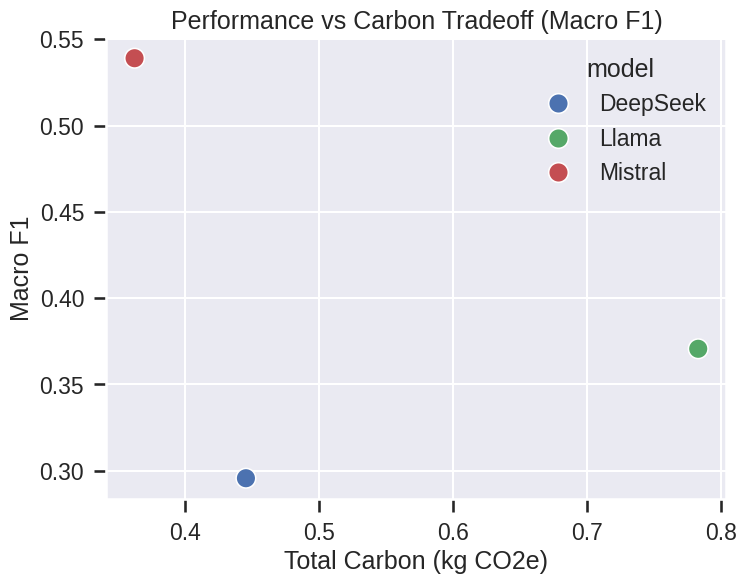

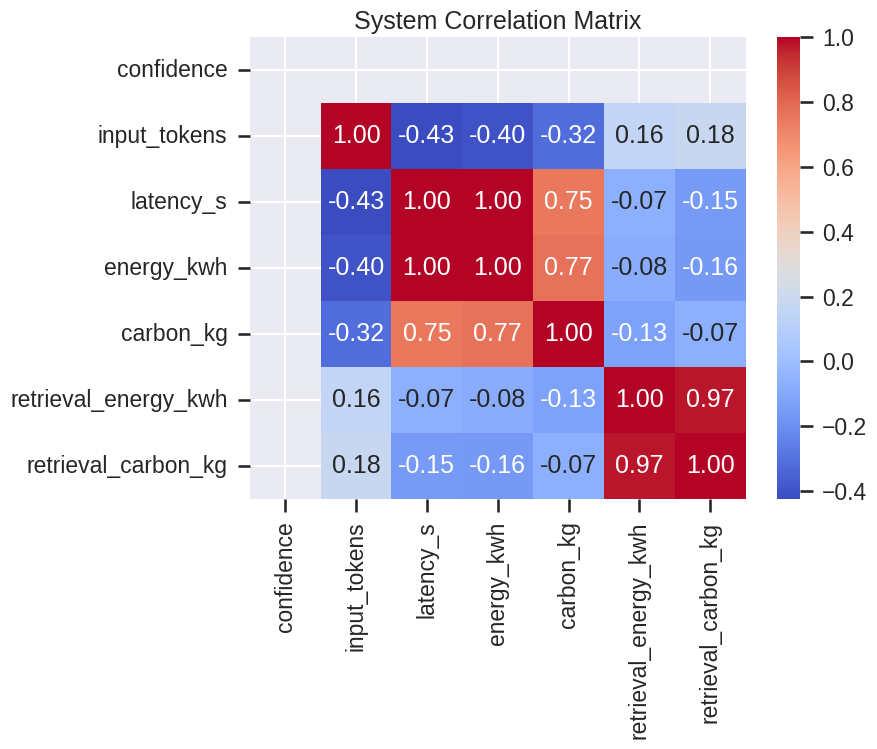

All strict evaluation files saved.


In [ ]:
!pip install -q seaborn scikit-learn tqdm

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

plt.style.use("seaborn-v0_8")
sns.set_context("talk")


ROOT_PATH = "/content/drive/MyDrive/RE_Result"



# Add full paths of ONLY the CSV files you want
SELECTED_CSV_FILES = [


]


def load_selected_results(csv_paths):

    all_data = []

    for file in csv_paths:
        try:
            df = pd.read_csv(file)

            path_parts = file.split("/")
            model_folder = [p for p in path_parts if p.endswith("_RE_Result")][0]
            dataset_folder = path_parts[-2]

            model_name = model_folder.replace("_RE_Result", "")

            df["model"] = model_name
            df["dataset_name"] = dataset_folder

            all_data.append(df)

        except Exception as e:
            print(f"Skipping {file} — {e}")

    return pd.concat(all_data, ignore_index=True)


print("Loading selected experiment results...")
df = load_selected_results(SELECTED_CSV_FILES)
def normalize_dataset(name):
    name = name.lower()

    if "cdn" in name or "ibm" in name:
        return "IBM_UAV_CDN"
    elif "open" in name:
        return "Open_Coss"
    elif "world" in name:
        return "World_Vista"
    elif name == "uav":
        return "UAV"
    elif "pure" in name:
        return "Pure"
    else:
        return name

df["dataset_name"] = df["dataset_name"].apply(normalize_dataset)

print("Datasets after normalization:")
print(df["dataset_name"].unique())


print("\nLoaded Summary:")
print("Total samples:", len(df))
print("Models:", df["model"].unique())
print("Datasets:", df["dataset_name"].unique())
print("Pipelines:", df["pipeline"].unique())


results = []

group_cols = ["model", "dataset_name", "pipeline"]

for keys, group in tqdm(df.groupby(group_cols)):
    model, dataset, pipeline = keys

    precision_macro = precision_score(
        group["ground_truth"],
        group["label"],
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        group["ground_truth"],
        group["label"],
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        group["ground_truth"],
        group["label"],
        average="macro",
        zero_division=0
    )

    results.append({
        "model": model,
        "dataset": dataset,
        "pipeline": pipeline,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "mean_latency": group["latency_s"].mean(),
        "mean_tokens": group["input_tokens"].mean(),
        "mean_energy": group["energy_kwh"].mean(),
        "mean_carbon": group["carbon_kg"].mean(),
        "total_carbon": group["carbon_kg"].sum(),
        "mean_retrieval_energy": group["retrieval_energy_kwh"].mean(),
        "mean_retrieval_carbon": group["retrieval_carbon_kg"].mean(),
        "mean_confidence": group["confidence"].mean(),
        "samples": len(group)
    })

metrics_df = pd.DataFrame(results)


model_summary = (
    metrics_df.groupby("model")
    .agg({
        "f1_macro": "mean",
        "mean_latency": "mean",
        "mean_energy": "mean",
        "total_carbon": "sum"
    })
    .reset_index()
)

model_summary["eco_score"] = (
    model_summary["f1_macro"] / model_summary["total_carbon"]
)

# Rankings
model_summary["rank_f1"] = model_summary["f1_macro"].rank(ascending=False)
model_summary["rank_latency"] = model_summary["mean_latency"].rank(ascending=True)
model_summary["rank_eco"] = model_summary["eco_score"].rank(ascending=False)

print("\nModel Leaderboard (Macro F1 + Latency + EcoScore):")
display(model_summary.sort_values("rank_f1"))


dataset_summary = (
    metrics_df.groupby(["dataset", "model"])
    .agg({
        "precision_macro": "mean",
        "recall_macro": "mean",
        "f1_macro": "mean",
        "total_carbon": "sum"
    })
    .reset_index()
)

print("\nDataset-wise Leaderboard (Macro Precision / Recall / F1):")
display(dataset_summary.sort_values(
    ["dataset", "f1_macro"],
    ascending=[True, False]
))


plt.figure(figsize=(8,6))
sns.scatterplot(
    data=model_summary,
    x="total_carbon",
    y="f1_macro",
    hue="model",
    s=200
)
plt.title("Performance vs Carbon Tradeoff (Macro F1)")
plt.xlabel("Total Carbon (kg CO2e)")
plt.ylabel("Macro F1")
plt.grid(True)
plt.show()

important_features = [
    "confidence",
    "input_tokens",
    "latency_s",
    "energy_kwh",
    "carbon_kg",
    "retrieval_energy_kwh",
    "retrieval_carbon_kg"
]

corr = df[important_features].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("System Correlation Matrix")
plt.show()


metrics_df.to_csv("/content/drive/MyDrive/SLM_strict_macro_metrics.csv", index=False)
model_summary.to_csv("/content/drive/MyDrive/SLM_strict_macro_model_summary.csv", index=False)
dataset_summary.to_csv("/content/drive/MyDrive/SLM_strict_macro_dataset_summary.csv", index=False)

print("All strict evaluation files saved.")